In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.inspection import PartialDependenceDisplay

k_format = FuncFormatter(lambda x, pos: f"${x/1000:.0f}K")

# Load the data if this notebook doesn't already have df in memory
if "df" not in globals():
    df = pd.read_csv("../figures/Housing.csv")   # change the path if your file is elsewhere
    bad_rows = (df["bedrooms"] > 10) | (df["bedrooms"] == 0) | (df["bathrooms"] == 0)
    df = df[~bad_rows].reset_index(drop=True)    # same cleaning as your notebook (21,595 rows)

d = df.copy()
d["date"] = pd.to_datetime(d["date"])
d["age"] = d["date"].dt.year - d["yr_built"]
d["renovated"] = (d["yr_renovated"] > 0).astype(int)

# Same house sold twice = same id, so we split by id to avoid leakage
print("rows:", len(d), "| repeat sales (same id):", d["id"].duplicated().sum())

features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront",
            "view", "condition", "grade", "sqft_above", "sqft_basement", "age",
            "renovated", "lat", "long", "sqft_living15", "sqft_lot15"]
X, y, groups = d[features], np.log(d["price"]), d["id"]

rows: 21595 | repeat sales (same id): 177


In [7]:

# %% Out-of-fold predictions for both models (every house predicted by a model that never saw it)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
gb = HistGradientBoostingRegressor(random_state=0)
cv = GroupKFold(n_splits=5)

d["pred_ridge"] = np.exp(cross_val_predict(ridge, X, y, cv=cv, groups=groups))
d["pred_gb"] = np.exp(cross_val_predict(gb, X, y, cv=cv, groups=groups))


def summary(pred):
    err = (pred - d["price"]).abs()
    ape = err / d["price"]
    return pd.Series({"MAE ($)": err.mean(), "median abs err ($)": err.median(),
                      "MAPE (%)": ape.mean() * 100,
                      "within 10% (%)": (ape < 0.10).mean() * 100,
                      "within 20% (%)": (ape < 0.20).mean() * 100})


print(pd.DataFrame({"ridge": summary(d["pred_ridge"]), "boosting": summary(d["pred_gb"])}).round(1))

                       ridge  boosting
MAE ($)             111832.2   65717.2
median abs err ($)   69287.1   38239.5
MAPE (%)                20.1      12.2
within 10% (%)          33.2      55.9
within 20% (%)          60.7      82.5


# %% Q1: where does it fail?

                n  median_price        MAE  MAPE      bias
price_band                                                
Q1 cheapest  4320      245000.0   35565.71  0.17  19504.21
Q2           4318      345000.0   36909.29  0.11   6604.03
Q3           4325      450000.0   48356.23  0.11   4741.03
Q4           4313      595000.0   60282.72  0.10 -11083.07
Q5 priciest  4319      887000.0  147488.81  0.13 -61503.16

Top 1% most expensive: 0.19 MAPE

15 biggest misses:
           price     pred_gb         err   ape  sqft_living  grade  waterfront  view  condition  yr_built  zipcode
7245   7700000.0  3791991.83 -3908008.17  0.51        12050     13           0     3          4      1910    98102
3910   7062500.0  3617983.98 -3444516.02  0.49        10040     11           1     2          3      1940    98004
9244   6885000.0  3546367.19 -3338632.81  0.48         9890     13           0     4          3      2001    98039
4407   5570000.0  3779680.79 -1790319.21  0.32         9200     13       

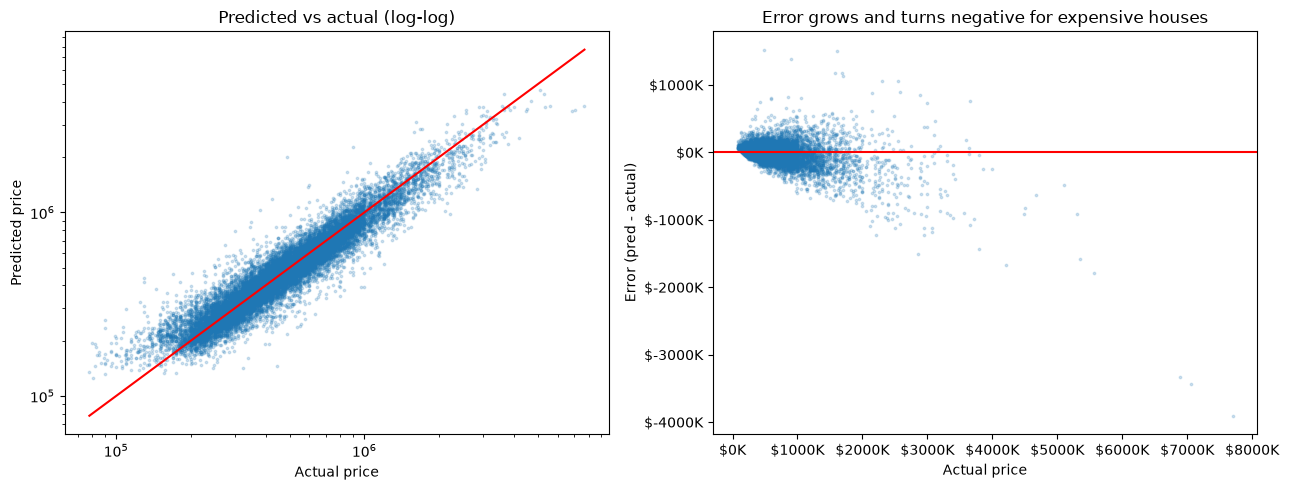

In [8]:
d["err"] = d["pred_gb"] - d["price"]
d["abs_err"] = d["err"].abs()
d["ape"] = d["abs_err"] / d["price"]
d["price_band"] = pd.qcut(d["price"], 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])

by_band = d.groupby("price_band", observed=True).agg(
    n=("price", "size"), median_price=("price", "median"),
    MAE=("abs_err", "mean"), MAPE=("ape", "mean"), bias=("err", "mean"))
print(by_band.round(2))   # bias < 0 means the model under-predicts

print("\nTop 1% most expensive:", d.loc[d["price"] > d["price"].quantile(0.99), "ape"].mean().round(3), "MAPE")

cols = ["price", "pred_gb", "err", "ape", "sqft_living", "grade", "waterfront", "view", "condition", "yr_built", "zipcode"]
print("\n15 biggest misses:")
print(d.nlargest(15, "abs_err")[cols].round(2).to_string())

# is the error concentrated in special segments?
for col in ["waterfront", "view", "grade"]:
    print(f"\nMAPE by {col}")
    print(d.groupby(col)["ape"].agg(["size", "mean"]).round(3).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(d["price"], d["pred_gb"], s=3, alpha=0.2)
lims = [d["price"].min(), d["price"].max()]
axes[0].plot(lims, lims, color="red")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price"); axes[0].set_title("Predicted vs actual (log-log)")
axes[1].scatter(d["price"], d["err"], s=3, alpha=0.2)
axes[1].axhline(0, color="red")
axes[1].xaxis.set_major_formatter(k_format); axes[1].yaxis.set_major_formatter(k_format)
axes[1].set_xlabel("Actual price"); axes[1].set_ylabel("Error (pred - actual)"); axes[1].set_title("Error grows and turns negative for expensive houses")
plt.tight_layout(); plt.show()

In [ ]:
#Q2: what does boosting capture that Ridge cannot?

In [11]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
gb = HistGradientBoostingRegressor(random_state=0)
cv = GroupKFold(n_splits=5)

d["pred_ridge"] = np.exp(cross_val_predict(ridge, X, y, cv=cv, groups=groups))
d["pred_gb"] = np.exp(cross_val_predict(gb, X, y, cv=cv, groups=groups))


def summary(pred):
    err = (pred - d["price"]).abs()
    ape = err / d["price"]
    return pd.Series({"MAE ($)": err.mean(), "median abs err ($)": err.median(),
                      "MAPE (%)": ape.mean() * 100,
                      "within 10% (%)": (ape < 0.10).mean() * 100,
                      "within 20% (%)": (ape < 0.20).mean() * 100})


print(pd.DataFrame({"ridge": summary(d["pred_ridge"]), "boosting": summary(d["pred_gb"])}).round(1))

                       ridge  boosting
MAE ($)             111832.2   65717.2
median abs err ($)   69287.1   38239.5
MAPE (%)                20.1      12.2
within 10% (%)          33.2      55.9
within 20% (%)          60.7      82.5


# %% Q3: is the typical error acceptable?

                n  median_price        MAE  MAPE      bias
price_band                                                
Q1 cheapest  4320      245000.0   35565.71  0.17  19504.21
Q2           4318      345000.0   36909.29  0.11   6604.03
Q3           4325      450000.0   48356.23  0.11   4741.03
Q4           4313      595000.0   60282.72  0.10 -11083.07
Q5 priciest  4319      887000.0  147488.81  0.13 -61503.16

Top 1% most expensive houses, MAPE: 0.19

15 biggest misses:
           price     pred_gb         err   ape  sqft_living  grade  waterfront  view  condition  yr_built  zipcode
7245   7700000.0  3791991.83 -3908008.17  0.51        12050     13           0     3          4      1910    98102
3910   7062500.0  3617983.98 -3444516.02  0.49        10040     11           1     2          3      1940    98004
9244   6885000.0  3546367.19 -3338632.81  0.48         9890     13           0     4          3      2001    98039
4407   5570000.0  3779680.79 -1790319.21  0.32         9200     1

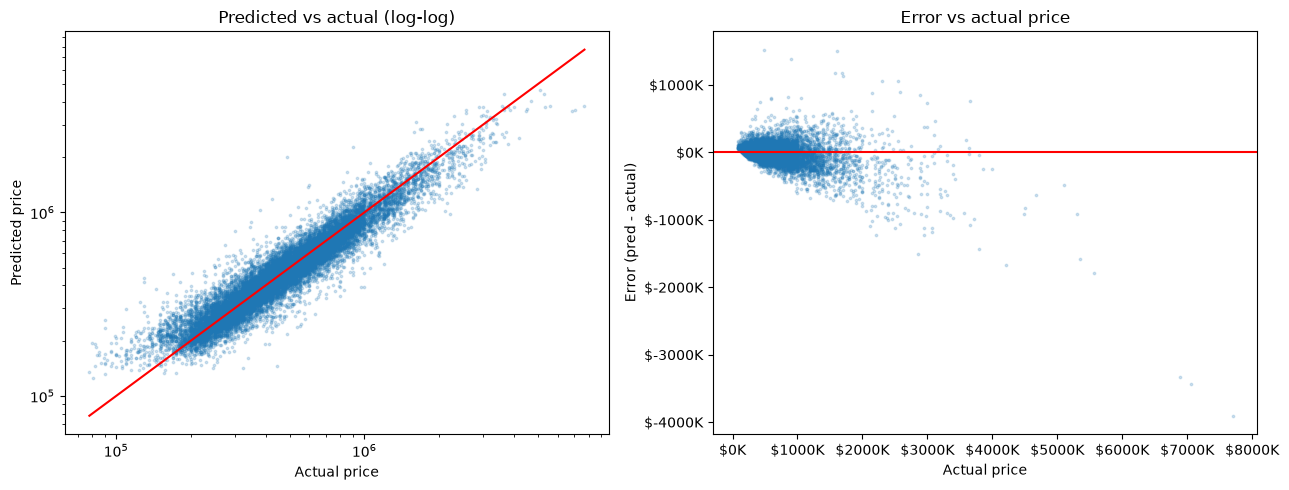

In [12]:
d["err"] = d["pred_gb"] - d["price"]          # negative = model under-predicts
d["abs_err"] = d["err"].abs()
d["ape"] = d["abs_err"] / d["price"]
d["price_band"] = pd.qcut(d["price"], 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])

by_band = d.groupby("price_band", observed=True).agg(
    n=("price", "size"), median_price=("price", "median"),
    MAE=("abs_err", "mean"), MAPE=("ape", "mean"), bias=("err", "mean"))
print(by_band.round(2))

top1 = d["price"] > d["price"].quantile(0.99)
print("\nTop 1% most expensive houses, MAPE:", d.loc[top1, "ape"].mean().round(3))

cols = ["price", "pred_gb", "err", "ape", "sqft_living", "grade", "waterfront",
        "view", "condition", "yr_built", "zipcode"]
print("\n15 biggest misses:")
print(d.nlargest(15, "abs_err")[cols].round(2).to_string())

for col in ["waterfront", "view", "grade"]:
    print(f"\nMAPE by {col}")
    print(d.groupby(col)["ape"].agg(["size", "mean"]).round(3).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(d["price"], d["pred_gb"], s=3, alpha=0.2)
lims = [d["price"].min(), d["price"].max()]
axes[0].plot(lims, lims, color="red")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Predicted vs actual (log-log)")
axes[1].scatter(d["price"], d["err"], s=3, alpha=0.2)
axes[1].axhline(0, color="red")
axes[1].xaxis.set_major_formatter(k_format); axes[1].yaxis.set_major_formatter(k_format)
axes[1].set_xlabel("Actual price"); axes[1].set_ylabel("Error (pred - actual)")
axes[1].set_title("Error vs actual price")
plt.tight_layout(); plt.show()
